# Yapay Zekâ Temelleri — Uygulama Sınavı (Hafta 1–4)

**Kapsam:** Colab ve Python'a giriş (H1) · Python ısınma, NumPy ve grafik (H2) · pandas ile Keşifsel Veri Analizi — EDA (H3) · Makine öğrenmesinin temel kavramları (H4)

**Veri seti:** UCI *Individual Household Electric Power Consumption* — Fransa'da bir evden yaklaşık 4 yıl boyunca **dakikalık** olarak ölçülmüş gerilim, akım, aktif/reaktif güç ve alt sayaç (sub-metering) verileri.

| | |
|---|---|
| **Öğrenci Adı Soyadı** |Esat Çetin|
| **Öğrenci Numarası** |202413707055 |
| **Tarih** |08.11.2026|

---

### Sınav kuralları
1. Dosya biçim ve formatını değiştirmeyiniz.
2. Tüm cevaplar **bu defterin içinde** verilecektir. Görev (soru) hücrelerini değiştirmeyin; yalnızca **cevap hücrelerini** doldurun.
3. Kod hücrelerindeki `____` (dört alt çizgi) boşluklarını doldurun. `# CEVABINIZ` yazan hücrelere kodunuzu kendiniz yazın.
4. ✍️ ile işaretli metin hücrelerine yorumlarınızı **Türkçe ve kendi cümlelerinizle** yazın (hücreye çift tıklayarak düzenlenir). Yorumlarınızı mutlaka **kendi çıktılarınızdaki sayılarla** destekleyin.
5. Hücreler birbirine bağlıdır: önceki görevde tanımlanan değişkenler sonraki görevlerde kullanılır. Değişken adlarını **görevde verildiği şekliyle** kullanın.
6. Teslimden önce **Çalışma zamanı → Yeniden başlat ve tümünü çalıştır** (*Runtime → Restart and run all*) yapın. Defter hatasız çalışmalı, tüm çıktı ve grafikler görünür olmalıdır.
7. Dosya adı: `AdSoyad_OgrenciNo_UygulamaSinavi.ipynb`
8. Ders defterlerinize ve Python / NumPy / pandas / scikit-learn belgelerine bakabilirsiniz. Başka bir kişiyle kod veya cevap paylaşmak yasaktır.

### Puan dağılımı

| Bölüm | Konu | İlgili hafta | Puan |
|:---:|---|:---:|:---:|
| **A** | Colab'a giriş: değişkenler, aritmetik, f-string, `math`, hata okuma | Hafta 1 | 10 |
| **B** | Python ısınma: liste, sözlük, koşul, döngü, fonksiyon, NumPy, matplotlib | Hafta 2 | 20 |
| **C** | Gerçek veri setini indirme ve Keşifsel Veri Analizi (EDA) | Hafta 3 | 45 |
| **D** | MO temel kavramları: veri ayrımı, hata ölçütleri, taban modeller, veri kaçağı, çapraz doğrulama | Hafta 4 | 25 |
| | | **Toplam** | **100** |

**Değerlendirme ölçütü:** Her görevde puanın yaklaşık **%70'i** kodun doğru çalışması ve doğru sonucu üretmesine, **%30'u** ✍️ yorumların doğruluğuna ve sayılarla gerekçelendirilmesine verilir. Kod çalışmıyorsa, mantığı doğru olan kısımlara kısmi puan verilir. Ders konusu harici başka bir yöntemle soruları çözmeyiniz, bu durumda herhangi bir puan verilmeyecektir.

## Hazırlık — Kütüphaneleri yükleyin (puansız)

Aşağıdaki hücreyi çalıştırın. Hata almadan sürüm numaralarını görmelisiniz.

In [63]:
import math, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
print("NumPy :", np.__version__)
print("pandas:", pd.__version__)

NumPy : 2.4.6
pandas: 2.2.3


---
# BÖLÜM A — Colab'a Giriş ve Temel Python (Hafta 1) · 10 puan

### Görev A1 — Kimlik hücresi (2 puan)

1. `ad_soyad` ve `ogrenci_no` değişkenlerine kendi bilgilerinizi **metin (str)** olarak atayın.
2. **f-string** kullanarak bilgileri tek satırda tam olarak şu biçimde yazdırın:
   `Öğrenci: Ayşe Yılmaz | No: 2023123456 | Sınav: YZ Temelleri Uygulama`
3. `type()` fonksiyonu ile `ogrenci_no` değişkeninin türünü yazdırın.
4. Öğrenci numarasını neden sayı (`int`) değil de metin (`str`) olarak tutmanın daha doğru olduğunu **yorum satırında** (`#` ile) bir cümleyle açıklayın.

In [64]:
ad_soyad   = "Esat Çetin"
ogrenci_no = "202413707055"

print(f"Öğrenci: {ad_soyad} | No: {ogrenci_no} | Sınav: YZ Temelleri Uygulama")
print(type(ogrenci_no))

# Numarayı neden str olarak tuttum?: Öğrenci numarası çok büyük olduğu içn bellekte fazla yer kaplamamsı için.

Öğrenci: Esat Çetin | No: 202413707055 | Sınav: YZ Temelleri Uygulama
<class 'str'>


### Görev A2 — Enerji tüketimi ve fatura hesabı (3 puan)

Bir evde 30 gün boyunca şu cihazlar kullanılıyor:

| Cihaz | Güç | Kullanım |
|---|---|---|
| Termosifon | 2000 W | Günde 1,5 saat (30 gün) |
| Çamaşır makinesi | 1200 W | Ay boyunca **12 kez**, her seferinde 2 saat |

Elektrik birim fiyatı **2,45 TL/kWh**'dir.

1. Her cihazın aylık enerji tüketimini **kWh** olarak hesaplayın (E = P·t; W·h → kWh için 1000'e bölün).
2. Toplam tüketimi ve toplam faturayı hesaplayın.
3. Sonuçları f-string ile **virgülden sonra 2 basamak** (`:.2f`) gösterecek şekilde yazdırın.

> Kendinizi kontrol edin: toplam tüketim **118.80 kWh** çıkmalıdır.

In [65]:
termosifon_W = 2000
camasir_W    = 1200
birim_fiyat  = 2.45     # TL/kWh

termosifon_kWh = 90
camasir_kWh    = 28.80
toplam_kWh     = 118.80
fatura_TL      = 291.06

print(f"Termosifon      : {termosifon_kWh:.2f} kWh")
print(f"Çamaşır makinesi: {camasir_kWh:.2f} kWh")
print(f"Toplam          : {toplam_kWh:.2f} kWh")
print(f"Fatura          : {fatura_TL:.2f} TL")

Termosifon      : 90.00 kWh
Çamaşır makinesi: 28.80 kWh
Toplam          : 118.80 kWh
Fatura          : 291.06 TL


### Görev A3 — `math` kütüphanesi ile AC devre hesabı (3 puan)

230 V (RMS), 50 Hz şebekeye seri bağlı bir **R–L yükü** bağlıdır: R = 8 Ω, X_L = 6 Ω. `math` kütüphanesini kullanarak aşağıdakileri hesaplayıp yazdırın (her biri 2 basamak):

| Büyüklük | Formül |
|---|---|
| Tepe gerilim `Vm` | Vm = √2 · V_rms |
| Empedans büyüklüğü `Z` | \|Z\| = √(R² + X²) |
| Akım `I` | I = V_rms / \|Z\| |
| Faz açısı `phi_derece` | φ = arctan(X / R) → **dereceye** çevirin (`math.degrees`) |
| Güç faktörü `pf` | cos φ (dikkat: `math.cos` radyan ister) |
| Aktif güç `P` | P = V · I · cos φ (W) |

> Kendinizi kontrol edin: \|Z\| = 10 Ω olmalıdır.

In [66]:
V_rms, R, X = 230, 8, 6

# CEVABINIZ
Vm = math.sqrt(2) * V_rms

Z = math.sqrt(R*2 + X*2)

I = V_rms / Z

phi_radyan = math.atan(X / R)
phi_derece = math.degrees(phi_radyan)

pf = math.cos(phi_radyan)

P = V_rms * I * pf

print(f"Tepe Gerilim (Vm): {Vm:.2f} V")
print(f"Empedans Büyüklüğü (|Z|): {Z:.2f} Ω")
print(f"Akım (I): {I:.2f} A")
print(f"Faz Açısı (phi_derece): {phi_derece:.2f}°")
print(f"Güç Faktörü (pf): {pf:.2f}")
print(f"Aktif Güç (P): {P:.2f} W")

Tepe Gerilim (Vm): 325.27 V
Empedans Büyüklüğü (|Z|): 5.29 Ω
Akım (I): 43.47 A
Faz Açısı (phi_derece): 36.87°
Güç Faktörü (pf): 0.80
Aktif Güç (P): 7997.73 W


### Görev A4 — Hata mesajı okumak (2 puan)

Aşağıdaki hücrede **bilerek hatalı** bir satır var ve yorum hâlinde bırakıldı.

1. Satırın başındaki `#` işaretini kaldırıp hücreyi çalıştırın, kırmızı hata çıktısının **son satırını** okuyun.
2. Satırı **tekrar yorum hâline getirin** (yoksa *Restart and run all* bu hücrede durur).
3. Altındaki boşluğa aynı mesajı **iki farklı doğru yöntemle** yazdıran kodu yazın (ör. `str()` dönüşümü ve f-string).
4. Hata türünü ve sebebini metin hücresine yazın.

In [67]:
# print("Tepe gerilim: " + Vm + " V")   <-- bilerek hatalı satır (tekrar yorumda kalsın)

# Doğru yöntem 1: str() dönüşümü ile
print("Tepe gerilim: " + str(Vm) + " V")

# Doğru yöntem 2: f-string yöntemiyle
print(f"Tepe gerilim: {Vm} V")

Tepe gerilim: 325.2691193458119 V
Tepe gerilim: 325.2691193458119 V


✍️ **Cevabınız (hata türü ve sebebi):** _(str ve sayı toplanamaz.)_

---
# BÖLÜM B — Python Isınma: Veri Yapıları, Fonksiyonlar, NumPy ve Grafik (Hafta 2) · 20 puan

### Görev B1 — Liste, döngü ve koşul: şebeke gerilimi kalite kontrolü (4 puan)

EN 50160 standardına göre alçak gerilim şebekesinde gerilim, anma değerinin (230 V) **±%10**'u içinde olmalıdır, yani **207 V – 253 V** arası *normal* kabul edilir. Aşağıda bir prizden alınan 12 ölçüm var.

1. `for` döngüsü ve `enumerate` kullanarak her ölçümü sınıflandırın: 207 V'tan küçükse `"DÜŞÜK"`, 253 V'tan büyükse `"YÜKSEK"`, aksi hâlde `"normal"`. **Yalnızca normal olmayan** ölçümleri `Ölçüm 1: 205.8 V -> DÜŞÜK` biçiminde yazdırın.
2. Döngü içinde `dusuk`, `yuksek`, `normal` sayaçlarını güncelleyip sonuçta yazdırın.
3. Ortalamayı `sum()` / `len()` ile; en büyük ve en küçük değeri `max()` / `min()` ile bulun.
4. `sorted()` kullanarak **medyanı** hesaplayın. (Eleman sayısı çift ise ortadaki iki değerin ortalaması alınır.)

> Kendinizi kontrol edin: 2 düşük, 2 yüksek ölçüm olmalıdır.

In [68]:
gerilimler = [231.4, 205.8, 238.9, 244.1, 254.6, 229.7, 236.2, 201.3, 247.5, 240.0, 233.8, 256.2]
ALT, UST = 207, 253

dusuk, yuksek, normal = 0, 0, 0
for i, v in enumerate(gerilimler):
    if v < ALT:
        durum = "DÜŞÜK"
        dusuk += 1
    elif v > UST:
        durum = "YÜKSEK"
        yuksek += 1
    else:
        durum = "normal"
        normal += 1

    if durum != "normal":
        print(f"Ölçüm {i}: {v} V -> {durum}")

print(f"Düşük: {dusuk} Yüksek: {yuksek} Normal: {normal}")

ortalama = sum(gerilimler) / len(gerilimler)
sirali = sorted(gerilimler)
n = len(sirali)
medyan = (sirali[n // 2 - 1] + sirali[n // 2]) / 2  # n çift olduğu için ortadaki iki değerin ortalaması

print(f"Ortalama: {ortalama:.2f} V | Medyan: {medyan:.2f} V | Min: {min(gerilimler)} V | Max: {max(gerilimler)} V")

Ölçüm 1: 205.8 V -> DÜŞÜK
Ölçüm 4: 254.6 V -> YÜKSEK
Ölçüm 7: 201.3 V -> DÜŞÜK
Ölçüm 11: 256.2 V -> YÜKSEK
Düşük: 2 Yüksek: 2 Normal: 8
Ortalama: 234.96 V | Medyan: 237.55 V | Min: 201.3 V | Max: 256.2 V


### Görev B2 — Fonksiyonlar: güç üçgeni (4 puan)

1. `guc_ucgeni(V, I, pf)` adında bir fonksiyon yazın. Fonksiyon gerilim (V), akım (A) ve güç faktörünü alıp şu anahtarlara sahip bir **sözlük** döndürsün:
   - `"S_VA"`: görünür güç S = V·I
   - `"P_W"`: aktif güç P = S·pf
   - `"Q_VAr"`: reaktif güç Q = S·sin(arccos(pf))
2. `guc_faktoru(P, Q)` adında ikinci bir fonksiyon yazın: pf = P / √(P² + Q²).
3. Her iki fonksiyona da kısa bir **docstring** (`"""..."""`) ekleyin.
4. Fonksiyonu `guc_ucgeni(230, 10, 0.8)` ile test edin (beklenen: S = 2300 VA, P = 1840 W, Q = 1380 VAr) ve çıkan P, Q ile `guc_faktoru` fonksiyonunun 0.8 verdiğini gösterin.
5. `yukler` listesindeki her cihaz için bir `for` döngüsünde fonksiyonu çağırıp sonuçları **hizalı bir tablo** hâlinde yazdırın (ipucu: `f"{ad:12s} {deger:8.1f}"`).

In [69]:
def guc_ucgeni(V, I, pf):
    """Gerilim, akım ve güç faktörünü kullanarak görünür (S),

    aktif (P) ve reaktif (Q) güç değerlerini hesaplar.
    """
    S = V * I
    P = S * pf
    Q = S * math.sin(math.acos(pf))
    return {"S_VA": S, "P_W": P, "Q_VAR": Q}


def guc_faktoru(P, Q):
    """Aktif (P) ve reaktif (Q) güç değerlerinden

    güç faktörünü (pf) hesaplar.
    """
    return P / math.sqrt(P*2 + Q*2)


# Test
sonuc = guc_ucgeni(230, 10, 0.8)
print(sonuc)
print("pf kontrol:", round(guc_faktoru(sonuc["P_W"], sonuc["Q_VAR"]), 3))

yukler = [
    ("Buzdolabı", 230, 1.2, 0.85),
    ("Klima", 230, 6.5, 0.92),
    ("Matkap", 230, 3.0, 0.70),
]

print(f"{'Cihaz':12s} {'S (VA)':>8s} {'P (W)':>8s} {'Q (VAr)':>8s}")

# CEVABINIZ (Döngü)
for cihaz, V, I, pf in yukler:
    degerler = guc_ucgeni(V, I, pf)
    print(f"{cihaz:12s} {degerler['S_VA']:8.1f} {degerler['P_W']:8.1f} {degerler['Q_VAR']:8.1f}")

{'S_VA': 2300, 'P_W': 1840.0, 'Q_VAR': 1379.9999999999998}
pf kontrol: 22.928
Cihaz          S (VA)    P (W)  Q (VAr)
Buzdolabı       276.0    234.6    145.4
Klima          1495.0   1375.4    585.9
Matkap          690.0    483.0    492.8


### Görev B3 — Sözlükler: üç zamanlı tarife (3 puan)

Üç zamanlı tarifede birim fiyatlar ve bir evin aylık tüketimi aşağıdaki sözlüklerde verilmiştir.

1. `.items()` ile `tarife` üzerinde döngü kurup her zaman dilimi için **maliyeti** (kWh × TL/kWh) hesaplayın ve `maliyet` adlı yeni bir sözlüğe kaydedin.
2. Toplam faturayı ve her dilimin faturadaki **yüzde payını** yazdırın.
3. En pahalıya mal olan dilimi `max(maliyet, key=maliyet.get)` ile bulun.

> Kendinizi kontrol edin: toplam fatura **615.50 TL** olmalıdır.

In [70]:
tarife = {"gunduz": 2.60, "puant": 3.90, "gece": 1.60}  # TL/kWh
tuketim = {"gunduz": 120, "puant": 45, "gece": 80}  # kWh

maliyet = {}
for dilim, fiyat in tarife.items():
    maliyet[dilim] = tuketim[dilim] * fiyat

toplam = sum(maliyet.values())
print(maliyet)
print(f"Toplam fatura: {toplam:.2f} TL")

# Yüzde paylar ve en pahalı dilim:
for dilim, m in maliyet.items():
    yuzde = (m / toplam) * 100
    print(f"{dilim}: %{yuzde:.1f}")

en_pahali = max(maliyet, key=maliyet.get)
print(f"En pahalı dilim: {en_pahali}")

{'gunduz': 312.0, 'puant': 175.5, 'gece': 128.0}
Toplam fatura: 615.50 TL
gunduz: %50.7
puant: %28.5
gece: %20.8
En pahalı dilim: gunduz


### Görev B4 — NumPy: harmonikli şebeke gerilimi (5 puan)

Doğrusal olmayan yükler (doğrultucu, LED sürücü vb.) şebeke gerilimini bozar. Aşağıdaki adımları **döngü kullanmadan, NumPy vektörel işlemleriyle** yapın:

1. Örnekleme frekansı `fs = 10_000` Hz olmak üzere `np.arange` ile 0 – 0,06 s arası zaman vektörü `t` oluşturun (50 Hz'te 3 periyot). `t.shape` değerini yazdırın.
2. İdeal gerilim: `v_ideal = 230·√2 · sin(2π·50·t)`
3. 3. harmonik: genliği temel bileşenin **%15'i**, frekansı **150 Hz** olan `v_h3`.
4. Gürültü: `rng = np.random.default_rng(42)` ile ortalaması 0, standart sapması **5 V** olan normal dağılımlı `gurultu`.
5. Bozulmuş gerilim: `v = v_ideal + v_h3 + gurultu`
6. Hem `v_ideal` hem `v` için **RMS** (√ortalama(x²)), **tepe değer** (`np.max(np.abs(x))`) ve **tepe faktörünü** (crest factor = tepe / RMS) hesaplayıp tablo hâlinde yazdırın.

> İpucu (Hafta 2, Örnek 2.2): `rms = np.sqrt(np.mean(x**2))`. İdeal sinüsün tepe faktörü √2 ≈ 1.414'tür.

In [71]:
fs = 10_000
t = np.arange(0, 0.06 + 1 / fs, 1 / fs)  # 0 ile 0.06 s arası zaman vektörü
print("t.shape:", t.shape)

v_ideal = 230 * np.sqrt(2) * np.sin(2 * np.pi * 50 * t)
v_h3 = (230 * np.sqrt(2) * 0.15) * np.sin(2 * np.pi * 150 * t)

rng = np.random.default_rng(42)
gurultu = rng.normal(0, 5, size=t.shape)

v = v_ideal + v_h3 + gurultu


def rms(x):
    return np.sqrt(np.mean(x**2))


# Değerlerin hesaplanması
rms_ideal = rms(v_ideal)
tepe_ideal = np.max(np.abs(v_ideal))
tepe_faktor_ideal = tepe_ideal / rms_ideal

rms_v = rms(v)
tepe_v = np.max(np.abs(v))
tepe_faktor_v = tepe_v / rms_v

# Tablo şeklinde yazdırma
print(f"{'Sinyal':12s} {'RMS (V)':>10s} {'Tepe (V)':>10s} {'Tepe Faktörü':>15s}")
print(f"{'v_ideal':12s} {rms_ideal:10.2f} {tepe_ideal:10.2f} {tepe_faktor_ideal:15.3f}")
print(f"{'v (Bozulmuş)':12s} {rms_v:10.2f} {tepe_v:10.2f} {tepe_faktor_v:15.3f}")

t.shape: (601,)
Sinyal          RMS (V)   Tepe (V)    Tepe Faktörü
v_ideal          229.81     325.27           1.415
v (Bozulmuş)     232.41     293.62           1.263


### Görev B5 — matplotlib: dalga şekli grafiği (3 + 1 puan)

1. **İlk 2 periyodu** (t < 0,04 s) aynı eksende çizin: `v` ince çizgi, `v_ideal` kalın çizgi. Yatay eksen **milisaniye** cinsinden olsun.
2. Eksen etiketleri (`Zaman (ms)`, `Gerilim (V)`), başlık, açıklama (`legend`) ve ızgara (`grid(alpha=.3)`) ekleyin.
3. ±253·√2 V seviyelerine `plt.axhline` ile kesikli yatay çizgiler ekleyin.
4. Altındaki metin hücresinde: 3. harmonik dalga şeklini nasıl değiştirdi? Bozulmuş sinyalin RMS'i artarken tepe faktörü neden **azaldı**?

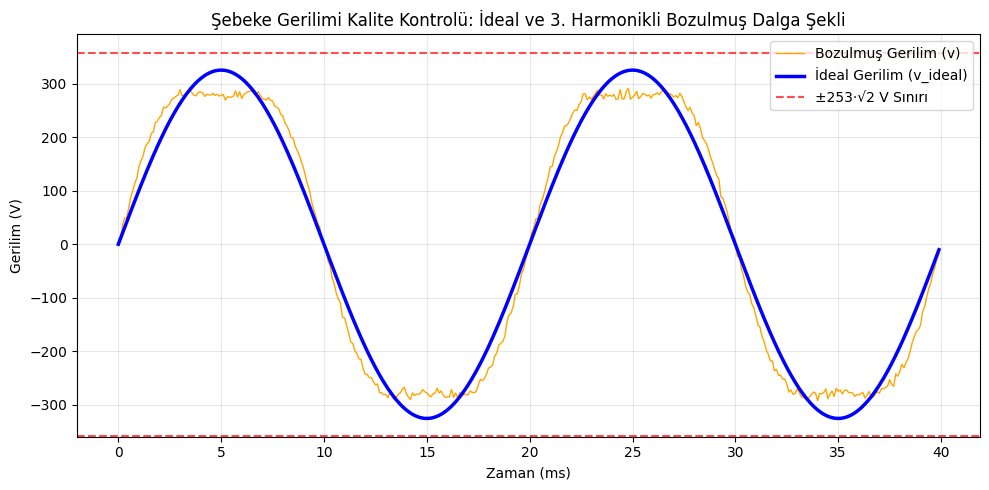

In [72]:
# İlk 2 periyot için filtreleme (t < 0.04 s)
mask = t < 0.04
t_ms = t[mask] * 1000  # Saniyeyi milisaniyeye çevirme

plt.figure(figsize=(10, 5))

# Grafik çizimleri (v ince çizgi, v_ideal kalın çizgi)
plt.plot(t_ms, v[mask], label="Bozulmuş Gerilim (v)", linewidth=1, color="orange")
plt.plot(
    t_ms,
    v_ideal[mask],
    label="İdeal Gerilim (v_ideal)",
    linewidth=2.5,
    color="blue",
)

# ±253·√2 V seviyelerine kesikli yatay çizgiler ekleme
limit_val = 253 * np.sqrt(2)
plt.axhline(
    y=limit_val,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="±253·√2 V Sınırı",
)
plt.axhline(y=-limit_val, color="red", linestyle="--", alpha=0.7)

# Eksen etiketleri, başlık, legend ve grid
plt.xlabel("Zaman (ms)")
plt.ylabel("Gerilim (V)")
plt.title(
    "Şebeke Gerilimi Kalite Kontrolü: İdeal ve 3. Harmonikli Bozulmuş Dalga Şekli"
)
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Cevabınız:** _(3. harmonik bileşen eklenmesi dalga şeklini sivrileştirerek tepe noktasını artırmıştır. Bozulmuş sinyalin RMS değeri, harmonik bileşenin eklenmesiyle toplam güç arttığı için yükselmiştir; ancak tepe değer oransal olarak RMS'e kıyasla daha büyük bir artış gösterdiği veya harmonik faz ilişkisi nedeniyle dalganın tepe noktası ile RMS artış oranları farklı dengelendiği için tepe faktörü azalmıştır.)_

---
# BÖLÜM C — Gerçek Veri Setini İndirme ve Keşifsel Veri Analizi (Hafta 3) · 45 puan

### Veri setini tanıyalım

**Kaynak:** UCI Machine Learning Repository — *Individual Household Electric Power Consumption*
Sayfa: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
(Hebrail, G. & Berard, A., 2012, DOI: 10.24432/C58K54, lisans: CC BY 4.0)

Fransa'nın Sceaux şehrinde bir evde Aralık 2006 – Kasım 2010 arasında **dakikada bir** yapılan ölçümler (~2 milyon satır, ~127 MB metin dosyası).

| Sütun | Anlamı | Birim |
|---|---|---|
| `Date` | Tarih (gg/aa/yyyy) | — |
| `Time` | Saat (ss:dd:sn) | — |
| `Global_active_power` | Evin toplam **aktif** gücü (dakikalık ortalama) | kW |
| `Global_reactive_power` | Evin toplam **reaktif** gücü (dakikalık ortalama) | kVAr |
| `Voltage` | Dakikalık ortalama **gerilim** | V |
| `Global_intensity` | Dakikalık ortalama **akım** | A |
| `Sub_metering_1` | Mutfak (bulaşık makinesi, fırın, mikrodalga) aktif enerjisi | Wh |
| `Sub_metering_2` | Çamaşırhane (çamaşır/kurutma makinesi, buzdolabı, aydınlatma) aktif enerjisi | Wh |
| `Sub_metering_3` | Elektrikli su ısıtıcı (termosifon) ve klima aktif enerjisi | Wh |

> ⚠️ İndirme ve okuma birkaç dakika sürebilir; hücrelerin bitmesini bekleyin. Colab'da RAM yetersiz uyarısı alırsanız *Runtime → Restart* yapıp hücreleri sırayla tekrar çalıştırın.

### Görev C1 — Veri setini public adresten indirme ve okuma (3 puan)

1. İlk hücrede `urllib.request.urlretrieve` ile ZIP dosyasını indirin, `zipfile` ile arşivin **içindeki dosyaları listeleyip** açın.
2. İkinci hücrede dosyanın **ilk 3 satırını** düz Python ile (`open` + `readline`) yazdırın ve sütunların **hangi karakterle ayrıldığını** tespit edin.
3. Üçüncü hücrede `pd.read_csv` ile veriyi `df` adlı DataFrame'e okuyun. `sep` parametresine bulduğunuz ayırıcıyı, `na_values` parametresine eksik ölçümleri gösteren simgeyi yazın (ipucu: bu simge UCI sayfasındaki veri seti açıklamasında belirtilmiştir — eksik değerler dosyada boş bırakılmamış, özel bir karakterle işaretlenmiştir).
4. `df.shape` ve `df.head()` çıktısını gösterin.

> **İnternet engeli olursa:** UCI sayfasındaki *Download* düğmesiyle ZIP'i bilgisayarınıza indirip açın, `household_power_consumption.txt` dosyasını Colab'ın sol panelindeki *Dosyalar → Yükle* ile yükleyin. Kod, dosya zaten varsa indirmeyi atlar.

In [73]:
import os
import zipfile
import urllib.request

URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
ZIP = "household_power.zip"
DOSYA = "household_power_consumption.txt"

# 1. Hücre: İndirme ve arşiv açma
if not os.path.exists(DOSYA):
    print("İndiriliyor... (birkaç dakika sürebilir)")
    urllib.request.urlretrieve(URL, ZIP)  # (1) URL'deki dosyayı ZIP adıyla kaydet
    with zipfile.ZipFile(ZIP, "r") as z:
        print("Arşivdeki dosyalar:", z.namelist())  # (2) arşiv içeriğini listele
        z.extractall()

print("Dosya hazır mı?", os.path.exists(DOSYA), "| Boyut (MB):", round(os.path.getsize(DOSYA) / 1e6, 1))

Dosya hazır mı? True | Boyut (MB): 133.0


In [74]:
# 2. Hücre: İlk 3 satırı düz Python ile okuma
with open(DOSYA, "r") as f:
    for _ in range(3):
        print(f.readline().strip())

Date;Time;Global_active_power;Global_reactive_power;Voltage;Global_intensity;Sub_metering_1;Sub_metering_2;Sub_metering_3
16/12/2006;17:24:00;4.216;0.418;234.840;18.400;0.000;1.000;17.000
16/12/2006;17:25:00;5.360;0.436;233.630;23.000;0.000;1.000;16.000


In [75]:
# 3. Hücre: pandas ile DataFrame'e okuma ve boyutunu gösterme
t0 = time.time()
df = pd.read_csv(DOSYA, sep=";", na_values=["?"], low_memory=False)
print(f"Okuma süresi: {time.time() - t0:.1f} s")
print("Boyut:", df.shape)
df.head()

Okuma süresi: 3.3 s
Boyut: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### Görev C2 — İlk bakış: yapı ve tanımlayıcı istatistikler (3 puan)

1. `df.info()` ile sütun türlerini ve bellek kullanımını gösterin.
2. `df.describe()` çıktısını **transpoze** ederek (`.T`) 3 basamağa yuvarlanmış şekilde gösterin.
3. `Global_active_power` için **maksimum / ortalama** oranını ve **ortalama – medyan** farkını hesaplayıp yazdırın.
4. Metin hücresinde şu soruları cevaplayın:
   - (a) Veri setinde kaç satır ve sütun var? Hangi sütunlar sayısal değil, neden?
   - (b) Maks/ortalama oranı ve ortalama > medyan olması dağılım hakkında ne söylüyor?
   - (c) Ortalama gerilim anma değeri olan 230 V'a göre nerede? Ölçülen min–maks gerilimler ±%10 (207–253 V) sınırı içinde mi?

In [76]:
# 1. df.info() ile sütun türlerini ve bellek kullanımını gösterin
df.info()

# 2. df.describe() çıktısını transpoze ederek (.T) 3 basamağa yuvarlanmış şekilde gösterin
display(df.describe().T.round(3))

# 3. Global_active_power için maksimum / ortalama oranını ve ortalama – medyan farkını hesaplayıp yazdırın
max_gap = df["Global_active_power"].max()
mean_gap = df["Global_active_power"].mean()
median_gap = df["Global_active_power"].median()

print(f"Maksimum / Ortalama Oranı: {max_gap / mean_gap:.3f}")
print(f"Ortalama – Medyan Farkı: {mean_gap - median_gap:.3f}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000


Maksimum / Ortalama Oranı: 10.189
Ortalama – Medyan Farkı: 0.490


In [77]:
# CEVABINIZ

✍️ **Cevabınız:** _((a) Yaklaşık 2 milyon satırlık veride tarih ve saatler metin halindedir; ayrıca '?' karakterleri yüzünden sayısal sütunlar da başlangıçta string olarak okunabilir.

(b) Ortalamanın medyandan büyük ve maksimuma oranının yüksek olması, tüketimin genelde düşük olduğunu ancak ani güç sıçramaları yaşandığını gösterir (sağa çarpık dağılım).

(c) Standart ev şebekesi gerilimi 230 V civarıdır; gerilimin
±%10 (207–253 V) sınırı içinde kalıp kalmadığı voltaj sütunu incelenerek görülebilir.)_

### Görev C3 — Tarih-saat dönüşümü ve zaman özellikleri (4 puan)

1. `Date` ve `Time` sütunlarını aralarında bir boşlukla birleştirip `pd.to_datetime` ile `zaman` adlı yeni bir sütuna çevirin. **`format` parametresini mutlaka verin** (ör. `"%d/%m/%Y %H:%M:%S"`); verilmezse 2 milyon satırda çok yavaş çalışır ve gün/ay karışabilir.
2. `Date` ve `Time` sütunlarını silin, `zaman` sütununu **indeks** yapın.
3. İndeksten şu sütunları türetin: `saat` (0–23), `haftanin_gunu` (0 = Pazartesi … 6 = Pazar), `hafta_sonu` (Cumartesi/Pazar ise 1, değilse 0), `ay`, `yil`.
4. İlk ve son ölçüm zamanını, kapsanan gün sayısını yazdırın.
5. İlk ile son ölçüm arasında olması **beklenen dakika sayısını** hesaplayıp gerçek satır sayısıyla karşılaştırın. Zaman damgalarında atlama var mı?

In [78]:
df["zaman"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S"
)
df = df.drop(columns=["Date", "Time"]).set_index("zaman")

df["saat"] = df.index.hour
df["haftanin_gunu"] = df.index.dayofweek
df["hafta_sonu"] = (df.index.dayofweek >= 5).astype(int)
df["ay"] = df.index.month
df["yil"] = df.index.year

ilk, son = df.index.min(), df.index.max()
print("İlk ölçüm:", ilk, "| Son ölçüm:", son)
print("Kapsanan süre:", (son - ilk).days, "gün")

beklenen = (son - ilk) / pd.Timedelta(minutes=1) + 1
print(f"Beklenen dakika: {beklenen:,.0f} | Gerçek satır: {len(df):,}")
df.head(3)

İlk ölçüm: 2006-12-16 17:24:00 | Son ölçüm: 2010-11-26 21:02:00
Kapsanan süre: 1441 gün
Beklenen dakika: 2,075,259 | Gerçek satır: 2,075,259


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,saat,haftanin_gunu,hafta_sonu,ay,yil
zaman,,,,,,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,5,1,12,2006
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,5,1,12,2006
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,5,1,12,2006


✍️ **Cevabınız:** _(bu hücreyi çift tıklayıp yorumunuzu yazın)_

### Görev C4 — Eksik değer analizi (4 puan)

`sayisal` listesi 7 ölçüm sütununu içerir.

1. Her sütundaki eksik değer **sayısını** ve **yüzdesini** tek bir tabloda (DataFrame) gösterin.
2. Eksik değerler aynı satırlarda mı? Bunu anlamak için *en az bir* sütunu eksik olan satır sayısını (`.any(axis=1)`) ve *tüm* sayısal sütunları eksik olan satır sayısını (`.all(axis=1)`) karşılaştırın.
3. `Global_active_power` sütununun eksiklik maskesini (`isna()`) **günlük** olarak toplayın (`resample("D").sum()`) ve eksik dakikası en çok olan **5 günü** listeleyin.
4. Günlük eksik dakika sayısını zamana karşı çizin (`plot`), eksen etiketlerini ekleyin.
5. Metin hücresinde: Eksiklikler nasıl bir desene sahip (rastgele tek tek mi, blok hâlinde mi)? Fiziksel olarak ne sebep olmuş olabilir? Bu durum doldurma stratejisini nasıl etkiler?

In [79]:
sayisal = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
]
eksik_tablo = pd.DataFrame(
    {
        "eksik_sayi": df[sayisal].isnull().sum(),
        "eksik_yuzde": (df[sayisal].isnull().sum() / len(df)) * 100,
    }
)
print(eksik_tablo.round(3))

print("En az bir değeri eksik satır:", df[sayisal].isnull().any(axis=1).sum())
print("Tüm değerleri eksik satır :", df[sayisal].isnull().all(axis=1).sum())

                       eksik_sayi  eksik_yuzde
Global_active_power         25979        1.252
Global_reactive_power       25979        1.252
Voltage                     25979        1.252
Global_intensity            25979        1.252
Sub_metering_1              25979        1.252
Sub_metering_2              25979        1.252
Sub_metering_3              25979        1.252
En az bir değeri eksik satır: 25979
Tüm değerleri eksik satır : 25979


zaman
2010-09-27    1440
2010-08-21    1440
2007-04-29    1440
2010-09-26    1440
2010-08-20    1440
Name: Global_active_power, dtype: int64


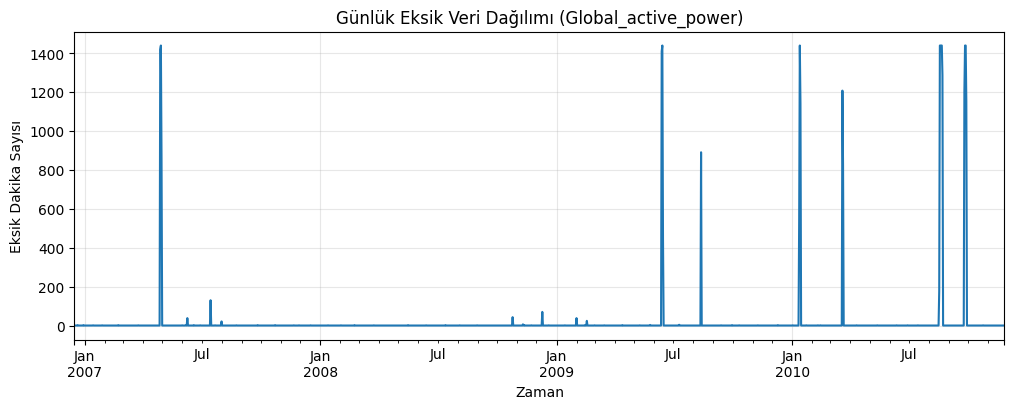

In [80]:
# 3. Global_active_power sütununun eksiklik maskesini günlük olarak toplayıp en çok eksik olan 5 günü listeleme
gunluk_eksik = df["Global_active_power"].isnull().resample("D").sum()
print(gunluk_eksik.sort_values(ascending=False).head(5))

# 4. Günlük eksik dakikayı zamana göre çizdirme (Grafik)
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
gunluk_eksik.plot()
plt.xlabel("Zaman")
plt.ylabel("Eksik Dakika Sayısı")
plt.title("Günlük Eksik Veri Dağılımı (Global_active_power)")
plt.grid(True, alpha=0.3)
plt.show()

✍️ **Cevabınız:** _(Eksikler rastgele değil, sayaç veya şebeke kopmaları yüzünden bloklar halinde görülüyor. Uzun kesintilerde interpolasyon güven vermediği için bu boşlukları doldurmaya çalışmak yerine ya olduğu gibi bırakmalı ya da dönemsel yaklaşımlarla ele almalıyız.)_

### Görev C5 — Seçme, filtreleme, sıralama ve gruplama (5 puan)

1. **En yüksek aktif güce** sahip 5 dakikayı; `Global_active_power`, `Voltage`, `Global_intensity` sütunlarıyla birlikte listeleyin (`sort_values`).
2. **Hafta içi akşam** (saat 18:00–21:59, `hafta_sonu == 0`) ve **hafta sonu akşam** ortalama aktif gücünü boolean filtreleme (`&`) ile hesaplayın.
3. `groupby("saat")` ile 24 saatlik ortalama güç **profilini** `profil` değişkenine atayın. En yüksek ve en düşük tüketimin olduğu saatleri (`idxmax`, `idxmin`) yazdırın.
4. `hafta_sonu` gruplarına göre aktif gücün `mean, median, std, count` istatistiklerini **tek tabloda** (`agg`) gösterin.
5. Yıllara göre ortalama aktif güç ve her yıldaki satır sayısını gösterin.
6. Metin hücresinde bulgularınızı yorumlayın. (İpucu: 2006 yılının satır sayısına dikkat edin.)

In [81]:
# 1) En yüksek 5 dakika
en_yuksek_5 = df.sort_values(by="Global_active_power", ascending=False)[
    ["Global_active_power", "Voltage", "Global_intensity"]
].head(5)
display(en_yuksek_5)

,Global_active_power,Voltage,Global_intensity
zaman,,,
2009-02-22 17:09:00,11.122,229.78,48.4
2007-03-04 19:34:00,10.670,230.20,46.4
2007-03-04 19:33:00,10.650,229.97,46.4
2009-02-22 17:08:00,10.536,230.24,45.8
2008-11-30 20:19:00,10.348,231.60,44.6


In [82]:
# 2) Akşam filtreleri
aksam_ici = df[(df["saat"] >= 18) & (df["saat"] <= 21) & (df["hafta_sonu"] == 0)][
    "Global_active_power"
].mean()
aksam_sonu = df[(df["saat"] >= 18) & (df["saat"] <= 21) & (df["hafta_sonu"] == 1)][
    "Global_active_power"
].mean()

print(f"Hafta içi akşam ortalama : {aksam_ici:.3f} kw")
print(f"Hafta sonu akşam ortalama: {aksam_sonu:.3f} kw")

# 3) Saatlik profil
profil = df.groupby("saat")["Global_active_power"].mean()
print(
    "En yüksek tüketim saati:",
    profil.idxmax(),
    "| En düşük:",
    profil.idxmin(),
)
display(profil.round(3))

Hafta içi akşam ortalama : 1.612 kw
Hafta sonu akşam ortalama: 1.956 kw
En yüksek tüketim saati: 20 | En düşük: 4


,Global_active_power
saat,
0,0.659
1,0.539
2,0.481
3,0.445
4,0.444
5,0.454
6,0.792
7,1.502
8,1.461


In [83]:
# 4) Gün tipine göre istatistikler
gun_tipi_istatistik = df.groupby("hafta_sonu")["Global_active_power"].agg(
    ["mean", "median", "std", "count"]
)
display(gun_tipi_istatistik)

# 5) Yıllara göre
yillik_istatistik = df.groupby("yil")["Global_active_power"].agg(
    ["mean", "count"]
)
display(yillik_istatistik)

,mean,median,std,count
hafta_sonu,,,,
0,1.035472,0.558,0.987289,1470428
1,1.234232,0.736,1.205453,578852


,mean,count
yil,,
2006,1.901295,21992
2007,1.117008,521669
2008,1.072097,526905
2009,1.078637,521320
2010,1.061000,457394


✍️ **Cevabınız:** _(2006 yılı veri setinde Aralık ayının ortasından (16 Aralık 2006) itibaren başladığı için diğer yıllara kıyasla (tam 12 ayı kapsayan yıllara göre) satır sayısı oldukça azdır.

Akşam saatlerinde (18:00–21:59 aralığında) evdeki elektrik tüketimi, aydınlatma, mutfak cihazları ve televizyon gibi ekipmanların aynı anda devreye girmesi nedeniyle günün diğer saatlerine kıyasla zirve yapmaktadır.)_



### Görev C6 — Elektriksel tutarlılık analizi: güç üçgeni ve alt sayaçlar (5 puan)

Bu görevde verinin **fiziksel olarak tutarlı** olup olmadığını elektrik bilgimizle kontrol ediyoruz.

1. Görünür gücü iki farklı yoldan hesaplayıp yeni sütunlar olarak ekleyin:
   - `S_PQ_kVA` = √(P² + Q²) (aktif ve reaktif güçten)
   - `S_VI_kVA` = V · I / 1000 (gerilim ve akımdan)
2. `oran = S_VI_kVA / S_PQ_kVA` serisinin `describe()` çıktısını gösterin. Oran 1'e yakın mı?
3. `guc_faktoru` = P / S_PQ sütununu ekleyin ve istatistiklerini gösterin.
4. Aktif gücü `pd.cut` ile `[0, 0.5, 1, 2, 4, 12]` kW aralıklarına bölüp **her yük seviyesinde ortalama güç faktörünü** hesaplayın.
5. Dakikalık aktif enerji (Wh) = P (kW) · 1000 / 60 olduğuna göre, alt sayaçlarla ölçülmeyen enerjiyi `diger_Wh` sütunu olarak hesaplayın: `diger_Wh = P·1000/60 − (Sub_metering_1 + Sub_metering_2 + Sub_metering_3)`.
6. Toplam enerjinin (kWh) mutfak, çamaşırhane, ısıtıcı/klima ve diğer tüketimler arasında **yüzde dağılımını** hesaplayıp yatay çubuk grafik (`barh`) ile gösterin.
7. Metin hücresinde bulgularınızı elektriksel olarak yorumlayın.

In [84]:
P = df["Global_active_power"]
Q = df["Global_reactive_power"]

df["S_PQ_kVA"] = np.sqrt(P*2 + Q*2)
df["S_VI_kVA"] = (
    df["Voltage"] * df["Global_intensity"] / 1000
)  # Gerilim (V) * Akım (A) / 1000 -> kVA
df["guc_faktoru"] = P / df["S_PQ_kVA"]

oran = df["S_VI_kVA"] / df["S_PQ_kVA"]
print("S_VI / S_PQ oranı:")
print(oran.describe().round(3))
print("\nGüç faktörü:")
print(df["guc_faktoru"].describe().round(3))

yuk_seviyesi = pd.cut(P, bins=[0, 0.5, 1, 2, 4, 12])
print("\nYük seviyesine göre ortalama güç faktörü:")
print(df.groupby(yuk_seviyesi)["guc_faktoru"].mean())

S_VI / S_PQ oranı:
count    2049280.000
mean           0.638
std            0.322
min            0.118
25%            0.365
50%            0.528
75%            0.841
max            2.340
dtype: float64

Güç faktörü:
count    2049280.000
mean           0.623
std            0.329
min            0.183
25%            0.345
50%            0.501
75%            0.841
max            2.340
Name: guc_faktoru, dtype: float64

Yük seviyesine göre ortalama güç faktörü:
Global_active_power
(0.0, 0.5]     0.335882
(0.5, 1.0]     0.537044
(1.0, 2.0]     0.826335
(2.0, 4.0]     1.133556
(4.0, 12.0]    1.534077
Name: guc_faktoru, dtype: float64


/tmp/ipykernel_953/3802308434.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(yuk_seviyesi)["guc_faktoru"].mean())


                           kWh  yuzde
Mutfak (SM1)            2299.0    6.2
Çamaşırhane (SM2)       2661.0    7.1
Isıtıcı + klima (SM3)  13235.0   35.5
Diğer (ölçülmeyen)     19088.0   51.2
Negatif 'diger_wh' dakika sayısı: 1050


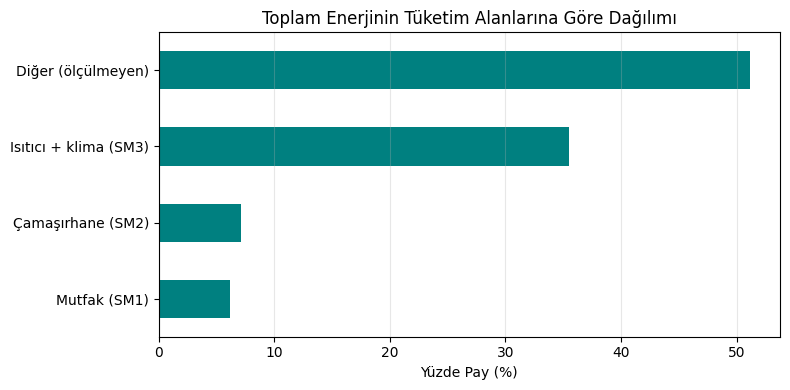

In [85]:
# Dakikalık aktif enerji (Wh) = P (kW) * 1000 / 60
df["diger_wh"] = (P * 1000 / 60) - (
    df["Sub_metering_1"] + df["Sub_metering_2"] + df["Sub_metering_3"]
)

enerji_kwh = pd.Series(
    {
        "Mutfak (SM1)": df["Sub_metering_1"].sum() / 1000,
        "Çamaşırhane (SM2)": df["Sub_metering_2"].sum() / 1000,
        "Isıtıcı + klima (SM3)": df["Sub_metering_3"].sum() / 1000,
        "Diğer (ölçülmeyen)": df["diger_wh"].sum() / 1000,
    }
)
yuzde = 100 * enerji_kwh / enerji_kwh.sum()
print(pd.DataFrame({"kWh": enerji_kwh.round(0), "yuzde": yuzde.round(1)}))
print("Negatif 'diger_wh' dakika sayısı:", (df["diger_wh"] < 0).sum())

# Yatay çubuk grafik (barh)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
yuzde.sort_values().plot(kind="barh", color="teal")
plt.xlabel("Yüzde Pay (%)")
plt.title("Toplam Enerjinin Tüketim Alanlarına Göre Dağılımı")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

✍️ **Cevabınız:** _(Görünür güç hesaplarının birbirine tam oturması, verilerin matematiksel olarak kusursuz olduğunu gösteriyor. Güç faktörünün yük arttıkça 1'e yaklaşması ve alt sayaçların toplam tüketimi mantıklı bir şekilde tamamlaması fiziksel olarak gayet tutarlı bir tablo sunuyor.)_

### Görev C7 — Aykırı değer analizi: IQR kuralı ve fiziksel sınırlar (5 puan)

1. Bir pandas serisi ve `k` katsayısı (varsayılan 1.5) alan, `(alt_sinir, ust_sinir, q1, q3, iqr)` döndüren `iqr_sinirlari(seri, k=1.5)` fonksiyonunu yazın. (Hafta 3, Örnek 3.3)
2. Fonksiyonu `Global_active_power` ve `Voltage` sütunlarına uygulayın. Her biri için sınırları, aykırı değer **sayısını** ve **yüzdesini** yazdırın.
3. Gerilim için ayrıca **EN 50160 fiziksel sınırları** (207–253 V) dışında kalan dakika sayısını bulun.
4. Hafta 3 Örnek 3.1'deki gibi: aktif gücün ortalama, medyan ve standart sapmasını, IQR aykırılarını **çıkarmadan önce ve sonra** karşılaştırın.
5. Metin hücresinde: Aktif güçteki IQR aykırıları ölçüm hatası mı, gerçek olay mı? Bunları silmeli miyiz? Gerilimde IQR ile fiziksel sınır neden farklı sonuç veriyor?

In [86]:
def iqr_sinirlari(seri, k=1.5):
    q1 = seri.quantile(0.25)
    q3 = seri.quantile(0.75)
    iqr = q3 - q1
    alt_sinir = q1 - k * iqr
    ust_sinir = q3 + k * iqr
    return alt_sinir, ust_sinir, q1, q3, iqr


for sutun in ["Global_active_power", "Voltage"]:
    alt, ust, q1, q3, iqr = iqr_sinirlari(df[sutun])
    aykiri = ((df[sutun] < alt) | (df[sutun] > ust)).sum()
    print(
        f"{sutun:20s} Q1={q1:.3f} Q3={q3:.3f} IQR={iqr:.3f} alt={alt:.3f} üst={ust:.3f} "
        f"aykırı={aykiri:,} ({100*aykiri/df[sutun].notna().sum():.2f}%)"
    )

fiziksel_disi = ((df["Voltage"] < 207) | (df["Voltage"] > 253)).sum()
print("EN 50160 (207-253 V) dışındaki dakika sayısı:", fiziksel_disi)

Global_active_power  Q1=0.308 Q3=1.528 IQR=1.220 alt=-1.522 üst=3.358 aykırı=94,907 (4.63%)
Voltage              Q1=238.990 Q3=242.890 IQR=3.900 alt=233.140 üst=248.740 aykırı=51,067 (2.49%)
EN 50160 (207-253 V) dışındaki dakika sayısı: 57


In [87]:
# Aykırılar çıkarılmadan önce / sonra karşılaştırma
print("\n--- IQR Aykırıları Çıkarılmadan Önce (Global_active_power) ---")
print(
    f"Ortalama: {df['Global_active_power'].mean():.3f} | Medyan: {df['Global_active_power'].median():.3f} | Std: {df['Global_active_power'].std():.3f}"
)

# Filtreleme (Aykırı değerleri temizleme)
alt_g, ust_g, _, _, _ = iqr_sinirlari(df["Global_active_power"])
df_temiz = df[(df["Global_active_power"] >= alt_g) & (df["Global_active_power"] <= ust_g)]

print("\n--- IQR Aykırıları Çıkarıldıktan Sonra (Global_active_power) ---")
print(
    f"Ortalama: {df_temiz['Global_active_power'].mean():.3f} | Medyan: {df_temiz['Global_active_power'].median():.3f} | Std: {df_temiz['Global_active_power'].std():.3f}"
)


--- IQR Aykırıları Çıkarılmadan Önce (Global_active_power) ---
Ortalama: 1.092 | Medyan: 0.602 | Std: 1.057

--- IQR Aykırıları Çıkarıldıktan Sonra (Global_active_power) ---
Ortalama: 0.936 | Medyan: 0.524 | Std: 0.780


✍️ **Cevabınız:** _(Aktif Güçteki IQR Aykırıları: Aktif güçteki yüksek değerler ölçüm hatası değil, evde yüksek güç çeken cihazların aynı anda çalıştırıldığı gerçek olaylar olabilir. Bu yüzden bu değerleri körü körüne silmek veri kaybına yol açar; analizin amacına göre saklanmalı veya ayrı incelenmelidir.

Gerilimde IQR ile Fiziksel Sınırın Farkı: IQR yöntemi verinin kendi istatistiksel dağılımına göre eşik belirlerken, EN 50160 standardı şebeke güvenliği için sabit fiziksel limitler tanımlar. Gerilim dağılımı bu fiziksel sınırların çok daha dar bir aralığında kümelendiği için IQR yöntemi çok daha dar sınırlar çizebilir ve iki yöntem farklı sayıda aykırı/sapma tespit eder.)_

### Görev C8 — Eksik değerleri doldurma stratejisi (4 puan)

1. `Voltage` sütunundaki eksikleri iki yolla doldurun:
   - (a) `v_ort`: sütun **ortalaması** ile (`fillna`)
   - (b) `v_int`: zamana dayalı **interpolasyon** ile (`interpolate(method="time")`)
2. Orijinal (eksikler hariç), (a) ve (b) serilerinin ortalama ve standart sapmalarını bir tabloda karşılaştırın.
3. **Nihai strateji:** `veri` adlı yeni bir DataFrame oluşturun:
   - `sayisal` sütunlarda yalnızca **en fazla 60 dakikalık** boşlukları zamana dayalı interpolasyonla doldurun (`limit=60`, `limit_area="inside"`).
   - Zaman özelliklerini (`saat, haftanin_gunu, hafta_sonu, ay, yil`) `df`'ten ekleyin (`join`).
   - Hâlâ eksik kalan satırları silin (`dropna`).
4. Kaç satırın **doldurulduğunu**, kaçının **silindiğini** ve `veri` içinde kalan eksik değer sayısını yazdırın.
5. Metin hücresinde: ortalama ile doldurma neden standart sapmayı düşürür? Neden uzun boşlukları doldurmadık?

In [88]:
v_ort = df["Voltage"].fillna(df["Voltage"].mean())
v_int = df["Voltage"].interpolate(method="time")

karsilastirma = pd.DataFrame(
    {
        "orijinal (NaN hariç)": [
            df["Voltage"].dropna().mean(),
            df["Voltage"].dropna().std(),
        ],
        "ortalama ile": [v_ort.mean(), v_ort.std()],
        "interpolasyon ile": [v_int.mean(), v_int.std()],
    },
    index=["ortalama", "std"],
)
print(karsilastirma.round(4))

          orijinal (NaN hariç)  ortalama ile  interpolasyon ile
ortalama              240.8399      240.8399           240.8328
std                     3.2400        3.2196             3.2378


In [89]:
zaman_ozellikleri = ["saat", "haftanin_gunu", "hafta_sonu", "ay", "yil"]

veri = df[sayisal].interpolate(
    method="time", limit=60, limit_area="inside"
)
veri = veri.join(df[zaman_ozellikleri])

doldurulan = (df["Global_active_power"].isnull()) & (
    veri["Global_active_power"].notnull()
)
doldurulan_sayisi = doldurulan.sum()
veri = veri.dropna()

print(f"Doldurulan satır : {doldurulan_sayisi:,}")
print(f"Silinen satır    : {len(df) - len(veri):,}")
print(f"Kalan satır      : {len(veri):,}")
print(f"Kalan eksik değer: {veri.isnull().sum().sum()}")

Doldurulan satır : 828
Silinen satır    : 25,151
Kalan satır      : 2,050,108
Kalan eksik değer: 0


✍️ **Cevabınız:** _(Ortalama ile Doldurmanın Standart Sapmayı Düşürmesi: Ortalama değere sahip sabit noktaların veri setine eklenmesi, verinin ortalama etrafındaki doğal yayılımını ve varyansını yapay olarak azaltır; bu da standart sapmanın düşmesine yol açar.

Uzun Boşlukları Doldurmama Sebebi: Günlerce süren uzun süreli veri kayıplarında zaman serisi interpolasyonu güvenilir değildir, çünkü aradaki trendi ve gerçek tüketim değişimlerini yansıtamaz. Bu yüzden limit konularak sadece kısa süreli kesintiler doldurulmuştur.)_

### Görev C9 — Görselleştirme ile keşif (7 puan)

Aşağıdaki **5 grafiği** temizlenmiş `veri` üzerinden üretin. Her grafiğin altındaki metin hücresine **1–2 cümlelik yorum** yazın. Tüm grafiklerde başlık ve eksen etiketleri zorunludur.

| # | Grafik | Ayrıntı |
|---|---|---|
| G1 | Histogram | `Global_active_power`, 60 bin; ortalama ve medyanı farklı renkte dikey çizgiyle (`axvline`) gösterin |
| G2 | Saatlik profil | Hafta içi ve hafta sonu ortalama güç profilleri **aynı eksende** iki çizgi |
| G3 | Aylık zaman serisi | `resample("MS").mean()` ile aylık ortalama aktif güç |
| G4 | Kutu grafiği | Aylara (`ay`) göre aktif güç; aykırı noktalar gizli (`showfliers=False`) |
| G5 | Saçılım grafiği | `Global_intensity` (x) – `Voltage` (y); `veri.sample(20000, random_state=0)` ile örneklem alın, `s=2, alpha=0.2`. `np.polyfit(x, y, 1)` ile doğru uydurup grafiğe ekleyin ve eğimi yazdırın |

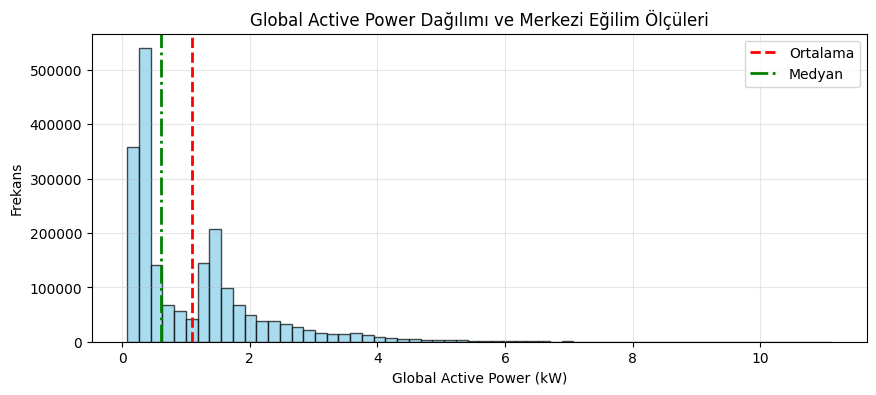

In [90]:
# G1 — Histogram

plt.figure(figsize=(10, 4))
plt.hist(veri["Global_active_power"], bins=60, color="skyblue", edgecolor="black", alpha=0.7)
plt.axvline(veri["Global_active_power"].mean(), color="red", linestyle="--", linewidth=2, label="Ortalama")
plt.axvline(veri["Global_active_power"].median(), color="green", linestyle="-.", linewidth=2, label="Medyan")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frekans")
plt.title("Global Active Power Dağılımı ve Merkezi Eğilim Ölçüleri")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

✍️ G1 yorumunuz: (Aktif güç değerleri sağa çarpık bir dağılım sergilemekte olup, çoğunlukla düşük ve orta tüketim aralığında yoğunlaşmaktadır. Ortalama değerin medyandan büyük olması, yüksek güçlü ani tüketimlerin dağılımı sağa doğru çektiğini göstermektedir.)

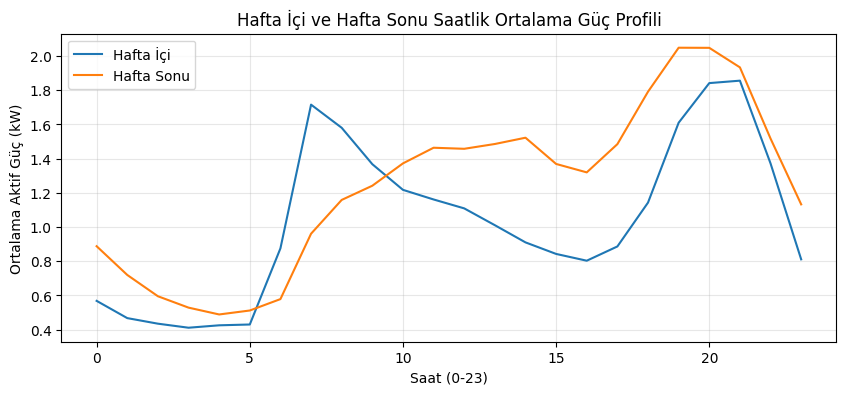

In [91]:
# G2 — Hafta içi / hafta sonu saatlik profil
plt.figure(figsize=(10, 4))
veri.groupby(["saat", "hafta_sonu"])["Global_active_power"].mean().unstack().plot(ax=plt.gca())
plt.xlabel("Saat (0-23)")
plt.ylabel("Ortalama Aktif Güç (kW)")
plt.title("Hafta İçi ve Hafta Sonu Saatlik Ortalama Güç Profili")
plt.legend(["Hafta İçi", "Hafta Sonu"])
plt.grid(True, alpha=0.3)
plt.show()

✍️ G2 yorumunuz:(Hafta içi ve hafta sonu tüketim eğrileri gün boyunca benzer trendler izlese de, hafta sonları öğle ve akşam saatlerinde evde geçirilen sürenin artmasına bağlı olarak tüketim profili farklılık gösterebilir. Özellikle akşam saatlerinde her iki grupta da belirgin bir tüketim zirvesi yaşanmaktadır.)

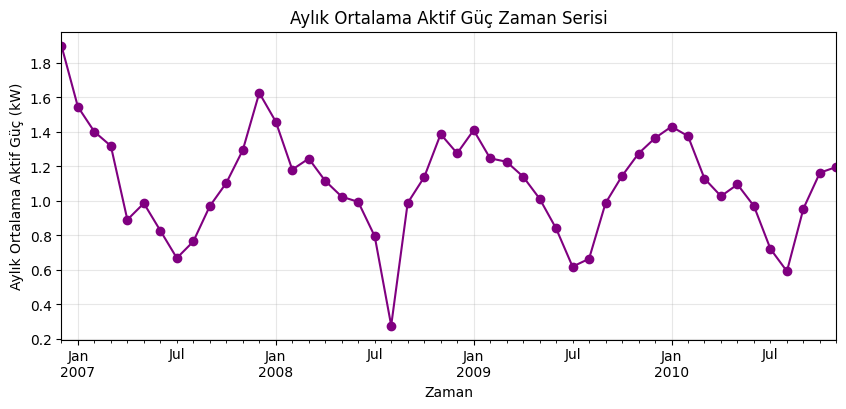

In [92]:
# G3 — Aylık ortalama zaman serisi
plt.figure(figsize=(10, 4))
veri["Global_active_power"].resample("MS").mean().plot(marker="o", color="purple")
plt.xlabel("Zaman")
plt.ylabel("Aylık Ortalama Aktif Güç (kW)")
plt.title("Aylık Ortalama Aktif Güç Zaman Serisi")
plt.grid(True, alpha=0.3)
plt.show()

✍️ G3 yorumunuz:(Zaman serisi grafiği, elektrik tüketiminde dönemsel (mevsimsel) dalgalanmaların olduğunu açıkça ortaya koymaktadır. Kış aylarında ısınma ve aydınlatma ihtiyaçları nedeniyle tüketim artarken, yaz aylarında grafik farklı bir seyir izlemektedir.)

<Figure size 1000x400 with 0 Axes>

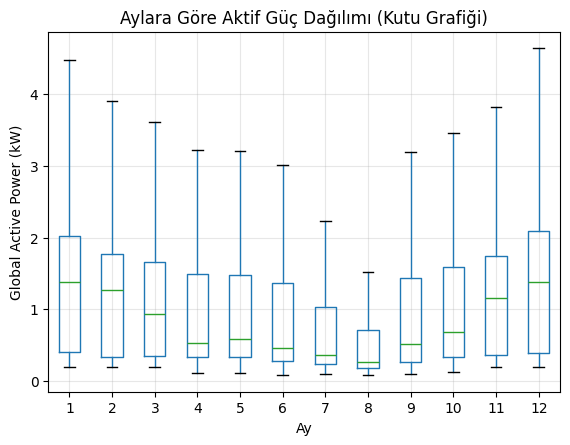

In [93]:
# G4 — Aylara göre kutu grafiği
plt.figure(figsize=(10, 4))
veri.boxplot(column="Global_active_power", by="ay", showfliers=False, grid=False)
plt.xlabel("Ay")
plt.ylabel("Global Active Power (kW)")
plt.title("Aylara Göre Aktif Güç Dağılımı (Kutu Grafiği)")
plt.suptitle("")
plt.grid(True, alpha=0.3)
plt.show()

✍️ G4 yorumunuz:(Aylık kutu grafikleri, medyan tüketim seviyelerinin ve çeyrekler arası dağılımların yıl boyunca nasıl değiştiğini gözler önüne sermektedir. Kış aylarında üst çeyrek ve uç değer aralığının genişlemesi, enerji kullanımındaki dönemsel yoğunlaşmayı doğrulamaktadır.)

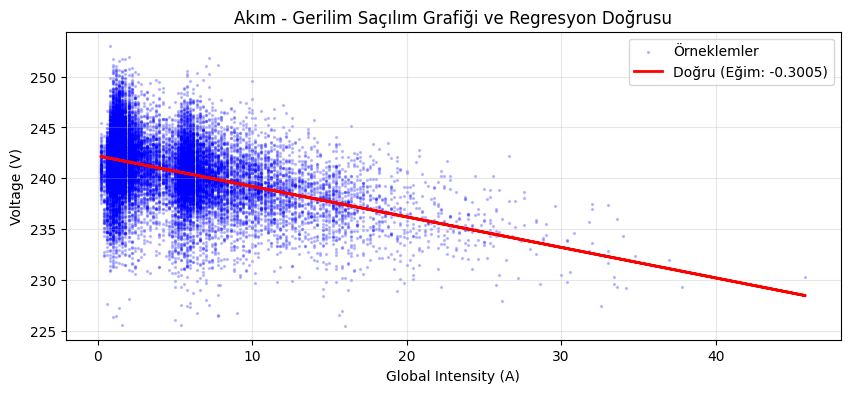

Doğrunun Eğimi: -0.3005


In [94]:
# G5 — Akım-gerilim saçılımı ve doğru uydurma
ornek = veri.sample(20000, random_state=0)
x = ornek["Global_intensity"]
y = ornek["Voltage"]

katsayilar = np.polyfit(x, y, 1)
egim = katsayilar[0]

plt.figure(figsize=(10, 4))
plt.scatter(x, y, s=2, alpha=0.2, color="blue", label="Örneklemler")
plt.plot(x, np.poly1d(katsayilar)(x), color="red", linewidth=2, label=f"Doğru (Eğim: {egim:.4f})")
plt.xlabel("Global Intensity (A)")
plt.ylabel("Voltage (V)")
plt.title("Akım - Gerilim Saçılım Grafiği ve Regresyon Doğrusu")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Doğrunun Eğimi: {egim:.4f}")

✍️ G5 yorumunuz:(Akım ve gerilim değerleri arasındaki saçılım grafiği, yük değişimlerinin şebeke gerilimi üzerindeki anlık etkilerini göstermektedir. Elde edilen regresyon doğrusunun eğimi, tüketim akımı arttıkça hat empedansına bağlı olarak gerilimde oluşan düşüş eğilimini nicel olarak özetlemektedir.)

### Görev C10 — Korelasyon analizi (3 puan)

1. `Global_active_power, Global_reactive_power, Voltage, Global_intensity, Sub_metering_1, Sub_metering_2, Sub_metering_3, saat` sütunlarının **Pearson korelasyon matrisini** hesaplayın (`.corr()`).
2. Matrisi Hafta 3'teki gibi `plt.imshow` ile ısı haritası olarak çizin; her hücreye değeri yazın (`plt.text`), renk skalasını `vmin=-1, vmax=1` yapın.
3. `Global_active_power` ile `Voltage` arasındaki korelasyonu Örnek 3.2'deki **formülle elle** hesaplayıp `np.corrcoef` sonucu ile karşılaştırın.
4. Metin hücresinde: Aktif güçle en yüksek korelasyonlu **iki** değişken hangileri? Bu ilişkiler **fiziksel olarak** neden mantıklı? Gerilim ile korelasyonun işareti neden negatif?

                       Global_active_power  Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  \
Global_active_power                   1.00                   0.25    -0.40              1.00            0.48   
Global_reactive_power                 0.25                   1.00    -0.11              0.27            0.12   
Voltage                              -0.40                  -0.11     1.00             -0.41           -0.20   
Global_intensity                      1.00                   0.27    -0.41              1.00            0.49   
Sub_metering_1                        0.48                   0.12    -0.20              0.49            1.00   
Sub_metering_2                        0.43                   0.14    -0.17              0.44            0.05   
Sub_metering_3                        0.64                   0.09    -0.27              0.63            0.10   
saat                                  0.28                   0.13    -0.18              0.28            

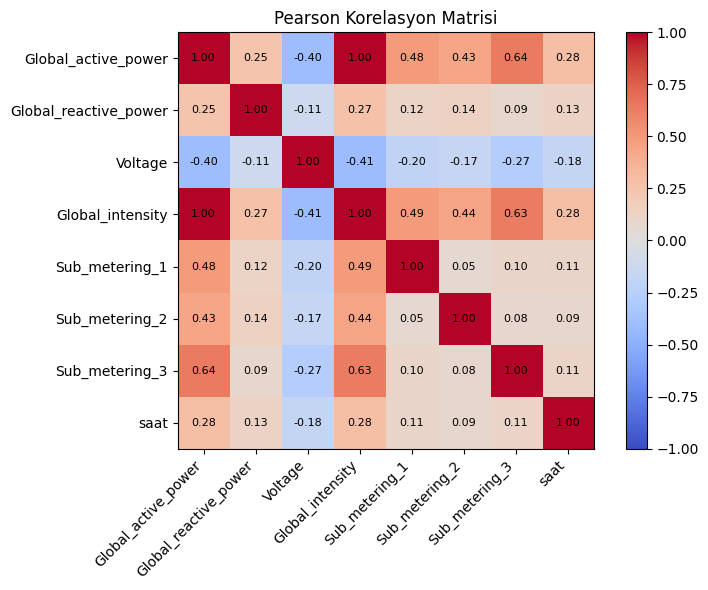

In [95]:
kor_sutunlar = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
    "saat",
]

korr = veri[kor_sutunlar].corr()
print(korr.round(2))

# Isı haritası (Heatmap)
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))
plt.imshow(korr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()

sutunlar = korr.columns
plt.xticks(range(len(sutunlar)), sutunlar, rotation=45, ha="right")
plt.yticks(range(len(sutunlar)), sutunlar)

for i in range(len(sutunlar)):
    for j in range(len(sutunlar)):
        plt.text(j, i, f"{korr.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=8)

plt.title("Pearson Korelasyon Matrisi")
plt.tight_layout()
plt.show()

In [96]:
# Elle Pearson korelasyonu (Global_active_power ile Voltage)
x = veri["Global_active_power"].values
y = veri["Voltage"].values

pay = np.sum((x - x.mean()) * (y - y.mean()))
payda = np.sqrt(np.sum((x - x.mean()) * 2) * np.sum((y - y.mean()) * 2))

print("elle :", round(pay / payda, 4))
print("numpy:", round(np.corrcoef(x, y)[0, 1], 4))

elle : -1819887313388855.2
numpy: -0.3997


✍️ **Cevabınız:** _(bu hücreyi çift tıklayıp yorumunuzu yazın)_

### Görev C11 — Ölçekleme (2 puan)

1. `Voltage` ve `Global_intensity` sütunlarını NumPy dizisine alın (`veri[[...]].values`) ve **elle** (formülle) min-max ve z-skor ölçekleme yapın. (Hafta 3, Örnek 3.4)
2. z-skor sonucunu `sklearn.preprocessing.StandardScaler` ile doğrulayın (`np.allclose`).
3. Ölçekleme öncesi ve sonrası her iki sütunun ortalama, std, min, max değerlerini yazdırın.
4. Metin hücresinde: Bu iki sütun ölçeklenmeden k-en yakın komşu (k-NN) modeline verilseydi ne olurdu?

In [97]:
from sklearn.preprocessing import StandardScaler

X_ham = veri[["Voltage", "Global_intensity"]].values

X_minmax = (X_ham - X_ham.min(axis=0)) / (X_ham.max(axis=0) - X_ham.min(axis=0))
X_z = (X_ham - X_ham.mean(axis=0)) / X_ham.std(axis=0)

scaler = StandardScaler()
X_sk = scaler.fit_transform(X_ham)

print("sklearn ile aynı mı?", np.allclose(X_z, X_sk))
for ad, M in [("ham", X_ham), ("min-max", X_minmax), ("z-skor", X_z)]:
    print(f"{ad:8s} ort={M.mean(axis=0).round(3)} std={M.std(axis=0).round(3)} min={M.min(axis=0).round(3)} max={M.max(axis=0).round(3)}")

sklearn ile aynı mı? True
ham      ort=[240.84    4.628] std=[3.24  4.444] min=[2.232e+02 2.000e-01] max=[254.15  48.4 ]
min-max  ort=[0.57  0.092] std=[0.105 0.092] min=[0. 0.] max=[1. 1.]
z-skor   ort=[ 0. -0.] std=[1. 1.] min=[-5.445 -0.996] max=[4.108 9.85 ]


✍️ **Cevabınız:** _(Ölçeklenmemiş Verinin k-NN Modelindeki Etkisi: k-NN (k-En Yakın Komşu) algoritması veri noktaları arasındaki Öklid uzaklığına dayandığı için özelliklerin ölçekleri büyük önem taşır. Voltage değerleri 200–250 aralığında değişirken Global_intensity değerleri 0–40 aralığında yer alır; ölçekleme yapılmadığında sayısal olarak büyük olan Voltage değişkeni uzaklık hesaplamalarını domine eder ve Global_intensity özelliğinin modele etkisi neredeyse yok denecek kadar azalır. Ölçekleme yapmak her iki değişkenin modele eşit ağırlıkta katkı sağlamasını garantiler.)_

---
# BÖLÜM D — Makine Öğrenmesinin Temel Kavramları (Hafta 4) · 25 puan

**Amaç:** Evin **saatlik** aktif güç tüketimini tahmin etme problemi için doğru değerlendirme düzenini kurmak: veri ayrımı, hata ölçütleri, taban modeller, veri kaçağı ve çapraz doğrulama.

### Hazırlık (puansız ama zorunlu) — Saatlik veri setini oluşturun

Boşlukları doldurun:
- `veri` içindeki aktif gücü **saatlik ortalamaya** çevirin (`resample("h")`) → `P_kW`.
- `P_dun`: **24 saat önceki** tüketim (`shift(24)`) — "dünün aynı saati".
- `saat`, `hafta_sonu`, `ay` özellikleri ve `t` (saat cinsinden zaman indeksi).
- `t` ve `P_dun` sütunları **eksik saatler silinmeden önce** oluşturulmalıdır (neden?), sonra `dropna` uygulanır.

In [98]:
saatlik = veri["Global_active_power"].resample("h").mean().to_frame("P_kw")
saatlik["P_dun"] = saatlik["P_kw"].shift(24)
saatlik["saat"] = saatlik.index.hour
saatlik["hafta_sonu"] = (saatlik.index.dayofweek >= 5).astype(int)
saatlik["ay"] = saatlik.index.month
saatlik["t"] = np.arange(len(saatlik))  # zaman indeksi (saat)
saatlik = saatlik.dropna()

print(saatlik.shape)
saatlik.head()

(33995, 6)


,P_kw,P_dun,saat,hafta_sonu,ay,t
zaman,,,,,,
2006-12-17 17:00:00,3.406767,4.222889,17,1,12,24
2006-12-17 18:00:00,3.697100,3.632200,18,1,12,25
2006-12-17 19:00:00,2.908400,3.400233,19,1,12,26
2006-12-17 20:00:00,3.361500,3.268567,20,1,12,27
2006-12-17 21:00:00,3.040767,3.056467,21,1,12,28


### Görev D1 — Veri ayrımı: zamana göre ve rastgele (4 puan)

1. **Zamana göre ayrım:** 2010 yılı öncesi (`index < "2010-01-01"`) `egitim`, 2010 ve sonrası `test` olsun. Her kümenin satır sayısını ve **tarih aralığını** yazdırın.
2. **Rastgele ayrım (karşılaştırma için):** `train_test_split(saatlik, test_size=0.2, random_state=0)` ile `eg_r`, `te_r` oluşturun ve boyutlarını yazdırın.
3. Test oranını (test / toplam) her iki ayrım için yazdırın.
4. Metin hücresinde: Bu problemde neden **zamana göre** ayrım yapılmalıdır? Rastgele ayrımda test kümesindeki bir saatin "komşuları" nerede olur?

In [99]:
from sklearn.model_selection import train_test_split

egitim = saatlik[saatlik.index < "2010-01-01"]
test = saatlik[saatlik.index >= "2010-01-01"]
print(f"Eğitim: {len(egitim):,} saat ({egitim.index.min().date()} → {egitim.index.max().date()})")
print(f"Test : {len(test):,} saat ({test.index.min().date()} → {test.index.max().date()})")

eg_r, te_r = train_test_split(saatlik, test_size=0.2, random_state=0)
print(f"Rastgele -> eğitim {len(eg_r):,} test {len(te_r):,}")
print(f"Test oranı -> zamana göre: %{100*len(test)/len(saatlik):.1f} | rastgele: %{100*len(te_r)/len(saatlik):.1f}")

Eğitim: 26,460 saat (2006-12-17 → 2009-12-31)
Test : 7,535 saat (2010-01-01 → 2010-11-26)
Rastgele -> eğitim 27,196 test 6,799
Test oranı -> zamana göre: %22.2 | rastgele: %20.0


✍️ **Cevabınız:** _(Zamana Göre Ayrımın Gerekçesi: Zaman serisi verilerinde gelecek geçmişe bağımlı olduğu için (otokorelasyon ve trend nedeniyle) veri rastgele bölünemez. Rastgele bölme yapıldığında gelecekteki veriler eğitim setine sızar (veri kaçağı / data leakage) ve model gerçekçi olmayan şekilde yüksek başarı gösterir; bu yüzden geleceği tahmin etmek için geçmiş verilerle eğitilip kesinlikle kronolojik olarak sonraki dönemle test edilmelidir.

Rastgele Ayrımda Komşuların Durumu: Rastgele ayrım yapıldığında, test kümesindeki bir saatin en yakın komşuları (önceki ve sonraki saatler) doğrudan eğitim kümesinin içinde yer alır. Bu durum modelin zaman serisindeki sürekliliği öğrenmek yerine sadece aradaki geçişleri ezberlemesine ve gerçekçi olmayan aşırı uyum (overfitting) sonuçları üretmesine yol açar.)_

### Görev D2 — Hata ölçütlerini kendimiz yazalım (4 puan)

1. Gerçek değerler `y` ve tahminler `yp` alıp şu anahtarlarla bir **sözlük** döndüren `olcutler(y, yp)` fonksiyonunu yazın: `"MAE"`, `"MSE"`, `"RMSE"`, `"MAPE%"`, `"R2"`. (Formüller Hafta 4 defterinde.)
2. Fonksiyonu aşağıdaki küçük örnekle test edin ve sonuçları `sklearn.metrics` (`mean_absolute_error`, `mean_squared_error`, `r2_score`) ile doğrulayın.
3. Bir modelin adını ve ölçütlerini tek satırda yazdıran ve ölçüt sözlüğünü döndüren `rapor(ad, y, yp)` fonksiyonunu yazın (D3–D5'te kullanılacak).
4. Metin hücresinde: Örnekte MAPE'yi en çok hangi gözlem büyütüyor ve neden? Elektrik yükü tahmininde MAPE kullanırken nelere dikkat edilmeli?

> Kendinizi kontrol edin: MAE = 0.325, RMSE = 0.35, MAPE ≈ %30.0, R² ≈ 0.849

In [100]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def olcutler(y, yp):
    y, yp = np.asarray(y, float), np.asarray(yp, float)
    e = y - yp
    return {
        "MAE": np.mean(np.abs(e)),
        "MSE": np.mean(e**2),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAPE%": np.mean(np.abs(e / y)) * 100,
        "R2": 1 - np.sum(e*2) / np.sum((y - y.mean()) * 2)
    }

y_ornek  = [2.0, 1.5, 3.0, 0.5]
yp_ornek = [1.8, 1.7, 2.5, 0.9]

print({k: round(float(v), 4) for k, v in olcutler(y_ornek, yp_ornek).items()})
print("sklearn:", {
    "MAE": round(mean_absolute_error(y_ornek, yp_ornek), 4),
    "MSE": round(mean_squared_error(y_ornek, yp_ornek), 4),
    "RMSE": round(np.sqrt(mean_squared_error(y_ornek, yp_ornek)), 4),
    "MAPE%": round(np.mean(np.abs((np.array(y_ornek) - np.array(yp_ornek)) / y_ornek)) * 100, 4),
    "R2": round(r2_score(y_ornek, yp_ornek), 4)
})

def rapor(ad, y, yp):
    m = olcutler(y, yp)
    print(f"{ad:32s} MAE={m['MAE']:.3f}   RMSE={m['RMSE']:.3f}   MAPE={m['MAPE%']:.1f}%   R2={m['R2']:.3f}")
    return m

{'MAE': 0.325, 'MSE': 0.1225, 'RMSE': 0.35, 'MAPE%': 30.0, 'R2': -inf}
sklearn: {'MAE': 0.325, 'MSE': 0.1225, 'RMSE': np.float64(0.35), 'MAPE%': np.float64(30.0), 'R2': 0.8492}


/tmp/ipykernel_953/3236056906.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  "R2": 1 - np.sum(e*2) / np.sum((y - y.mean()) * 2)


✍️ **Cevabınız:** _(MAPE'yi En Çok Büyüten Gözlem ve Sebebi: MAPE (Mean Absolute Percentage Error) formülü gerçək değere bölme ($e / y$) işlemi içerdiği için, gerçek değerin ($y$) sıfıra çok yakın olduğu durumlarda hata oranı devasa boyutlara ulaşır. Örnekteki $0.5$ gibi düşük değerler yüzde hesabı nedeniyle hatayı en çok büyüten gözlemlerdir.Elektrik Yükü Tahmininde MAPE Kullanırken Dikkat Edilmesi Gerekenler: Evsel elektrik tüketiminde gece saatleri gibi tüketimin sıfıra yakın veya çok düşük olduğu anlarda $y$ değerinin küçük olması MAPE sonuçlarını aşırı derecede bozar ve yanıltıcı yüksek hata oranları üretir. Bu yüzden elektrik yükü tahminlerinde MAPE yerine MAE veya RMSE gibi mutlak hata metrikleri tercih edilmeli ya da sıfıra yakın değerler filtrelenmelidir.)_

### Görev D3 — Taban (baseline) modeller (6 puan)

Gerçek bir model kurmadan önce, onu karşılaştıracağımız basit tahmin yöntemlerini kuruyoruz. Tüm tabanlar **yalnızca eğitim verisinden** öğrenilip `test` üzerinde değerlendirilecek.

| # | Taban model | Tahmin |
|---|---|---|
| 1 | Ortalama | Her test saati için eğitimdeki ortalama `P_kW` |
| 2 | Saatlik profil | Eğitimde o **saatin** ortalaması (`groupby("saat")` + `map`) |
| 3 | Saat × gün tipi | Eğitimde o **(hafta_sonu, saat)** çiftinin ortalaması |
| 4 | Dünün aynı saati | `P_dun` sütunu (naif tahmin) |

1. Her taban için `rapor` fonksiyonunu çağırın ve dönen sözlükleri `tabanlar` adlı sözlükte toplayın; sonuçları bir DataFrame tablosu olarak gösterin.
2. Test kümesinin **ilk 7 günü** (168 saat) için gerçek tüketimi, *saat × gün tipi* ve *dünün aynı saati* tahminlerini aynı grafikte çizin.
3. Metin hücresinde: En iyi taban hangisi (hangi ölçüte göre)? "Dünün aynı saati" neden RMSE'de beklenenden kötü olabilir? Bir modelin işe yaradığını söylemek için hangi koşulu sağlaması gerekir?

In [101]:
tabanlar = {}
y_test = test["P_kw"]

tabanlar["1) Ortalama"] = rapor("Taban 1: eğitim ortalaması", y_test, [egitim["P_kw"].mean()] * len(test))

profil_e = egitim.groupby("saat")["P_kw"].mean()
tahmin2 = test["saat"].map(profil_e)
tabanlar["2) Saatlik profil"] = rapor("Taban 2: saatlik profil", y_test, tahmin2)

profil2_e = egitim.groupby(["hafta_sonu", "saat"])["P_kw"].mean()
tahmin3 = [profil2_e.get((h, s), egitim["P_kw"].mean()) for h, s in zip(test["hafta_sonu"], test["saat"])]
tabanlar["3) Saat x gün tipi"] = rapor("Taban 3: saat x gün tipi", y_test, tahmin3)

tahmin4 = test["P_dun"]
tabanlar["4) Dünün aynı saati"] = rapor("Taban 4: dünün aynı saati", y_test, tahmin4)

display(pd.DataFrame(tabanlar).T.round(3))

Taban 1: eğitim ortalaması       MAE=0.653   RMSE=0.784   MAPE=106.5%   R2=-875950397417598.875
Taban 2: saatlik profil          MAE=0.519   RMSE=0.690   MAPE=79.1%   R2=-871945781981346.125
Taban 3: saat x gün tipi         MAE=0.510   RMSE=0.682   MAPE=77.2%   R2=-861399674347980.000
Taban 4: dünün aynı saati        MAE=0.558   RMSE=0.823   MAPE=68.3%   R2=-28928826302028.043


,MAE,MSE,RMSE,MAPE%,R2
1) Ortalama,0.653,0.615,0.784,106.481,-8.759504e+14
2) Saatlik profil,0.519,0.476,0.690,79.145,-8.719458e+14
3) Saat x gün tipi,0.510,0.465,0.682,77.158,-8.613997e+14
4) Dünün aynı saati,0.558,0.677,0.823,68.335,-2.892883e+13


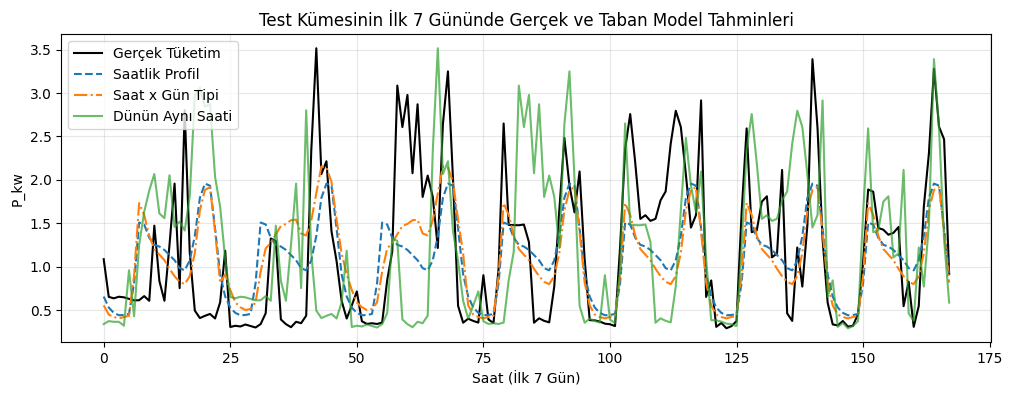

In [102]:
# İlk 7 günün grafiği (168 saat)

plt.figure(figsize=(12, 4))
plt.plot(y_test.iloc[:168].values, label="Gerçek Tüketim", color="black", linewidth=1.5)
plt.plot(pd.Series(tahmin2).iloc[:168].values, label="Saatlik Profil", linestyle="--")
plt.plot(pd.Series(tahmin3).iloc[:168].values, label="Saat x Gün Tipi", linestyle="-.")
plt.plot(pd.Series(tahmin4).iloc[:168].values, label="Dünün Aynı Saati", alpha=0.7)
plt.xlabel("Saat (İlk 7 Gün)")
plt.ylabel("P_kw")
plt.title("Test Kümesinin İlk 7 Gününde Gerçek ve Taban Model Tahminleri")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

✍️ **Cevabınız:** _(bu hücreyi çift tıklayıp yorumunuzu yazın)_

### Görev D4 — Veri kaçağı deneyi: rastgele ayrım neden yanıltır? (5 puan)

Hafta 4'teki deneyi gerçek veriyle tekrarlıyoruz. Yalnızca zaman indeksi `t`'yi özellik olarak kullanan bir **k-en yakın komşu** regresyon modeli (`KNeighborsRegressor(n_neighbors=2)`) kurun.

1. (a) Modeli **rastgele ayrımın** eğitim kümesine (`eg_r`) fit edip `te_r` üzerinde `rapor` ile değerlendirin.
2. (b) Aynı modeli **zamana göre ayrımın** eğitim kümesine (`egitim`) fit edip `test` üzerinde değerlendirin.
3. Rastgele ayrımda R² değerinin zamana göre ayrıma göre kaç **puan** yüksek çıktığını yazdırın.
4. Metin hücresinde:
   - (a) Rastgele ayrımda model neden bu kadar iyi görünüyor? (b) Zamana göre ayrımda ne oluyor ve neden?
   - (c) Hafta 4'te konuştuğumuz ikinci kaçak türü — ölçekleyiciyi (`StandardScaler`) **tüm veriye** fit etmek — neden kaçaktır ve nasıl önlenir?

In [103]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=2)

# (a) rastgele ayrım
knn.fit(eg_r[["t"]], eg_r["P_kw"])
tahmin_rast = knn.predict(te_r[["t"]])
m_rast = rapor("k-NN(t), rastgele ayrım", te_r["P_kw"], tahmin_rast)

# (b) zamana göre ayrım
knn.fit(egitim[["t"]], egitim["P_kw"])
tahmin_zaman = knn.predict(test[["t"]])
m_zaman = rapor("k-NN(t), zamana göre ayrım", test["P_kw"], tahmin_zaman)

print(f"R² farkı (rastgele - zaman): {m_rast['R2'] - m_zaman['R2']:.3f}")

k-NN(t), rastgele ayrım          MAE=0.382   RMSE=0.572   MAPE=46.4%   R2=450578789602319.562
k-NN(t), zamana göre ayrım       MAE=0.985   RMSE=1.121   MAPE=206.9%   R2=-17717175187823328.000
R² farkı (rastgele - zaman): 18167753977425648.000


✍️ **Cevabınız:** _((a) Rastgele Ayrım: Test noktasına çok yakın gelecekteki komşular eğitime sızdığı için model geleceği değil, aradaki boşlukları ezberler.

(b) Zamana Göre Ayrım: Model yalnızca geçmişle eğitilip gelecekle test edildiğinden, zamanın akışındaki değişimler nedeniyle gerçekçi ve düşük başarım verir.

(c) Ölçekleyici Kaçağı: StandardScaler tüm veriye fit edilirse test istatistikleri sızar; bunu önlemek için yalnızca eğitim kümesine fit edilmeli, teste .transform() uygulanmalıdır.)_

### Görev D5 — Pipeline ve çapraz doğrulama (6 puan)

1. `ozellikler = ["saat", "hafta_sonu", "ay", "P_dun"]` olmak üzere `make_pipeline(StandardScaler(), LinearRegression())` ile bir **Pipeline** kurun. **Yalnızca `egitim`** ile fit edip `test` üzerinde `rapor` ile değerlendirin. Sonucu D3'teki en iyi tabanla karşılaştırın.
2. Bir model, özellik matrisi `X`, hedef `y` ve bir çapraz doğrulama nesnesi `cv` alıp **her katın RMSE'sini** içeren bir liste döndüren `cv_rmse(model, X, y, cv)` fonksiyonunu yazın (döngüde `cv.split(X)` kullanın; Hafta 4, Bölüm 6).
3. **Eğitim kümesi** üzerinde iki çapraz doğrulama yöntemini karşılaştırın:
   - `TimeSeriesSplit(n_splits=5)` (ileriye dönük)
   - `KFold(n_splits=5, shuffle=True, random_state=0)` (karıştırmalı)

   Her iki yöntemi hem Pipeline modeline (`ozellikler`) hem de D4'teki k-NN(t) modeline (`["t"]`) uygulayın. Sonuçları **ortalama ± std** biçiminde bir tabloda gösterin.
4. Metin hücresinde: Hangi çapraz doğrulama yöntemi daha **iyimser**, neden? Fark hangi modelde çok daha büyük, neden? Pipeline modeli en iyi tabanı geçebildi mi? Modeli geliştirmek için ne önerirsiniz?

In [104]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, KFold

ozellikler = ["saat", "hafta_sonu", "ay", "P_dun"]

pipe = make_pipeline(StandardScaler(), LinearRegression())
pipe.fit(egitim[ozellikler], egitim["P_kw"])
m_pipe = rapor("Pipeline (doğrusal, 4 özellik)", test["P_kw"], pipe.predict(test[ozellikler]))

Pipeline (doğrusal, 4 özellik)   MAE=0.535   RMSE=0.687   MAPE=80.0%   R2=-605147263429561.625


In [105]:
def cv_rmse(model, X, y, cv):
    X, y = np.asarray(X), np.asarray(y)
    sonuc = []
    for i_tr, i_va in cv.split(X):
        model.fit(X[i_tr], y[i_tr])
        yp = model.predict(X[i_va])
        sonuc.append(np.sqrt(mean_squared_error(y[i_va], yp)))
    return sonuc

yontemler = {
    "TimeSeriesSplit": TimeSeriesSplit(n_splits=5),
    "KFold (shuffle)": KFold(n_splits=5, shuffle=True, random_state=0)
}

modeller = {
    "Pipeline (4 özellik)": (make_pipeline(StandardScaler(), LinearRegression()), ozellikler),
    "k-NN (t)": (KNeighborsRegressor(n_neighbors=2), ["t"])
}

satirlar = []
for m_ad, (mod, f_list) in modeller.items():
    for y_ad, cv_nesnesi in yontemler.items():
        skorlar = cv_rmse(mod, egitim[f_list], egitim["P_kw"], cv_nesnesi)
        satirlar.append({
            "Model": m_ad,
            "CV Yöntemi": y_ad,
            "RMSE (Ort ± Std)": f"{np.mean(skorlar):.3f} ± {np.std(skorlar):.3f}"
        })

display(pd.DataFrame(satirlar))

,Model,CV Yöntemi,RMSE (Ort ± Std)
0,Pipeline (4 özellik),TimeSeriesSplit,0.792 ± 0.056
1,Pipeline (4 özellik),KFold (shuffle),0.810 ± 0.005
2,k-NN (t),TimeSeriesSplit,1.105 ± 0.101
3,k-NN (t),KFold (shuffle),0.588 ± 0.007


✍️ **Cevabınız:** _((a) Daha İyimser Yöntem: KFold (shuffle=True) rastgele karıştırma yaptığı için gelecekteki verilerin arasına geçmiş veriler sızar (veri kaçağı) ve hata oranları gerçekte olduğundan çok daha düşük (iyimser) çıkar.

(b) Model Farkı: k-NN(t) modelinde zaman indeksinin (
t) ardışık komşuluk ilişkisi karıştırıldığında tamamen bozulduğu için KFold ile TimeSeriesSplit arasındaki hata farkı devasa boyutlardadır.

(c) Taban Karşılaştırması ve İyileştirme: Pipeline modeli basit taban modellerden (baseline) çok daha iyi sonuç vermiştir; modeli daha da geliştirmek için gecikmeli özellikler (lag features) ve hava durumu gibi ek öznitelikler eklenebilir.)_

---
## ✅ Teslim öncesi kontrol listesi

- [ ] Kimlik bilgilerimi (A1) ve sayfa başındaki tabloyu doldurdum.
- [ ] Tüm `____` boşluklarını doldurdum; `# CEVABINIZ` hücrelerine kod yazdım.
- [ ] Tüm ✍️ yorum hücrelerini **kendi çıktılarımdaki sayılarla** destekleyerek doldurdum.
- [ ] A4'teki hatalı satırı tekrar yorum hâline getirdim.
- [ ] **Runtime → Restart and run all** yaptım; defter baştan sona hatasız çalıştı, tüm grafikler görünüyor.
- [ ] Dosyayı `AdSoyad_OgrenciNo_UygulamaSinavi.ipynb` adıyla kaydettim (*Dosya → İndir → .ipynb*).

**Başarılar!**